In [273]:
import pandas as pd
import re
import os #pour naviguer dans les dossiers
from io import StringIO
import s3fs #pour connecter au bucket

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt



In [274]:


# Create filesystem object
S3_ENDPOINT_URL = "https://" + os.environ["AWS_S3_ENDPOINT"]
fs = s3fs.S3FileSystem(client_kwargs={'endpoint_url': S3_ENDPOINT_URL})

BUCKET_OUT = "aluneau"

last_file="anonymous_answer_2026-07-24.csv"


In [275]:
with fs.open(f"{BUCKET_OUT}/data_eP8/raw/{last_file}", "r") as file_in:
    df0 = pd.read_csv(file_in, sep =",")


In [276]:
df_col = pd.read_csv("../le_questionnaire/dico_variable.csv", sep = ",")

# Profil disciplinaire

In [277]:
def split_multiple_choices(data, column, index, sep = '|'):
    """
    split and explode column with multiple value

    data = a panda dataframe
    column = name of column which we want to split.
    index = column corresponding to id of rows
    sep = by default '|'. Character use to separate values.
    """
    df_split = data.copy()
    df_split[column] = df_split[column].str.split(sep)
    df_explode = df_split.explode(column)
    gb_data = df_explode.groupby([column]).agg(nb = (index, "size")).reset_index()
    gb_data["total"] = data[index].nunique()
    gb_data["freq"] = gb_data.nb/gb_data.total*100
    gb_data["total_freq"] = gb_data.total/gb_data.total*100

    return gb_data, df_explode

In [278]:
gb_data, df_exp = split_multiple_choices(df0, column='q10_type_data', index = "q45_clé", sep = ';')
gb_data1, df_exp1 = split_multiple_choices(df0, column='q5_logiciel_traitement_rec', index = "q45_clé", sep = '|')


In [279]:
df_rf = df_exp[["q45_clé", 'q10_type_data']].copy()
df_rf.loc[df_rf.q10_type_data.isna(), "q10_type_data"] = "Aucune donnée"
df_rf.loc[df_rf.q10_type_data=="Aucune donnée"]
df_rf["value"] = "Oui"
df_rf["question"] = 'q10_type_data'

df_rf["nb"] = df_rf.groupby(["q10_type_data"])["q45_clé"].transform("count")
df_rf["value_int"] = 1

In [280]:
df_d = df_exp1[["q45_clé", 'q5_logiciel_traitement_rec']].copy()
df_d.loc[df_d.q5_logiciel_traitement_rec.isna(), "q5_logiciel_traitement_rec"] = "Aucun logiciel"
df_d.loc[df_d.q5_logiciel_traitement_rec=="Aucun logiciel"]
df_d["value"] = "Oui"
df_d["question"] = 'q5_logiciel_traitement_rec'
df_d["nb"] = df_d.groupby(["q5_logiciel_traitement_rec"])["q45_clé"].transform("count")
df_d["value_int"] = 1


In [281]:
df_df=pd.concat([df_d.rename(columns={"q5_logiciel_traitement_rec":"variable"}), df_rf.rename(columns={"q10_type_data":"variable"},)])
#df_df = df_df.loc[~df_df.variable.isna()]


In [282]:
def create_term_term_matrix(data, what, list_columns, value, fill_value=0):
    table = pd.pivot_table(data, 
                           values=value, index=what, columns=list_columns, aggfunc=np.sum, fill_value=fill_value)
    
    #term_term = np.dot(table, table.T) # multiplication de la transposé de
    return table

In [283]:
table = create_term_term_matrix(data = df_df,  what ="q45_clé", list_columns=["variable"], value="value", fill_value="Non")
table2 = create_term_term_matrix(data = df_df,  what ="q45_clé", list_columns=["variable"], value="value_int", fill_value=0)

/tmp/ipykernel_791/4196202599.py:2: FutureWarning: The provided callable <function sum at 0x7f4ded40eac0> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  table = pd.pivot_table(data,
/tmp/ipykernel_791/4196202599.py:2: FutureWarning: The provided callable <function sum at 0x7f4ded40eac0> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  table = pd.pivot_table(data,


In [284]:
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [285]:
sns.set(context='notebook', style='white', rc={'figure.figsize':(14,10)})

In [286]:
#analyse avec fanalysis
from fanalysis.mca import MCA

In [287]:
for col in table.columns:
    print(col)
    table[col] = table.apply(lambda row: f'{col}_{str(row[col])}', 1) # lower sentence
table

Aucun logiciel
Aucune
Autre, précisez lesquelles
Données d'enquête
Données d'entretien
Données du web
Données expérimentales ou d'observation
Données géographiques ou spatiales
Données multimédia
Données statistiques
Données textuelles ou documentaires
Métadonnées
access
activetigger
asp
atlas.ti
bash
c#
c/c++
caml
css
csv
cuda
d3.js
endnotes
excel
file maker pro
gdl
gephi
google sheets
grist
html
ia
iramuteq
jamovi
jasp
javascript
julia
latex
libreoffice calc
limesurvey
ludii
matlab
maxqda
mplus
neo4j
nvivo
ocaml
php
python
qgis
qualcoder
r
racket
sas
spss
stata
statistica
xml
zotero


variable,Aucun logiciel,Aucune,"Autre, précisez lesquelles",Données d'enquête,Données d'entretien,Données du web,Données expérimentales ou d'observation,Données géographiques ou spatiales,Données multimédia,Données statistiques,...,qgis,qualcoder,r,racket,sas,spss,stata,statistica,xml,zotero
q45_clé,,,,,,,,,,,,,,,,,,,,,
2DRU-P3AV,Aucun logiciel_Non,Aucune_Non,"Autre, précisez lesquelles_Non",Données d'enquête_Oui,Données d'entretien_Oui,Données du web_Oui,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Oui,Données statistiques_Non,...,qgis_Non,qualcoder_Non,r_Non,racket_Non,sas_Non,spss_Non,stata_Non,statistica_Non,xml_Non,zotero_Non
2JQN-P9PA,Aucun logiciel_Non,Aucune_Non,"Autre, précisez lesquelles_Non",Données d'enquête_Non,Données d'entretien_Non,Données du web_Non,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Non,...,qgis_Non,qualcoder_Non,r_Oui,racket_Non,sas_Non,spss_Non,stata_Non,statistica_Non,xml_Non,zotero_Non
2QNC-8AAQ,Aucun logiciel_Oui,Aucune_Non,"Autre, précisez lesquelles_Non",Données d'enquête_Oui,Données d'entretien_Oui,Données du web_Non,Données expérimentales ou d'observation_Non,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Non,...,qgis_Non,qualcoder_Non,r_Non,racket_Non,sas_Non,spss_Non,stata_Non,statistica_Non,xml_Non,zotero_Non
2Y89-7BR9,Aucun logiciel_Non,Aucune_Non,"Autre, précisez lesquelles_Non",Données d'enquête_Non,Données d'entretien_Oui,Données du web_Non,Données expérimentales ou d'observation_Non,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Non,...,qgis_Non,qualcoder_Non,r_Non,racket_Non,sas_Non,spss_Non,stata_Non,statistica_Non,xml_Non,zotero_Non
32TW-JLY5,Aucun logiciel_Non,Aucune_Non,"Autre, précisez lesquelles_Non",Données d'enquête_Oui,Données d'entretien_Non,Données du web_Oui,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Oui,Données statistiques_Oui,...,qgis_Non,qualcoder_Non,r_Non,racket_Non,sas_Non,spss_Non,stata_Non,statistica_Non,xml_Non,zotero_Non
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,Aucun logiciel_Non,Aucune_Non,"Autre, précisez lesquelles_Non",Données d'enquête_Oui,Données d'entretien_Oui,Données du web_Oui,Données expérimentales ou d'observation_Non,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Oui,...,qgis_Non,qualcoder_Non,r_Non,racket_Non,sas_Non,spss_Non,stata_Non,statistica_Non,xml_Non,zotero_Non
YTMC-B4DP,Aucun logiciel_Non,Aucune_Non,"Autre, précisez lesquelles_Non",Données d'enquête_Oui,Données d'entretien_Oui,Données du web_Non,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Oui,Données statistiques_Oui,...,qgis_Non,qualcoder_Oui,r_Oui,racket_Non,sas_Non,spss_Non,stata_Non,statistica_Non,xml_Non,zotero_Non
ZB5S-ABHN,Aucun logiciel_Non,Aucune_Non,"Autre, précisez lesquelles_Non",Données d'enquête_Non,Données d'entretien_Oui,Données du web_Non,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Oui,...,qgis_Non,qualcoder_Non,r_Oui,racket_Non,sas_Non,spss_Non,stata_Non,statistica_Non,xml_Non,zotero_Non


In [294]:
np.sum(table2["Aucune"])

np.int64(5)

In [298]:
# Sélection variables actives (utilisées pour construire les facteurs) et les variables illustratives
var_active = [var for var in table2.columns if np.sum(table2[var])>9]
var_illust = [var for var in table.columns if np.sum(table2[var])<=9 and np.sum(table2[var])>2]
var_illust = var_illust + ['label_recherche_1','hc_label','hc_methodo_9','hc_methodo_8','hc_methodo_6','clust_type_data']

# Individus actifs et supplémentaires
table3 = table2[var_active].copy()

ind_supp =[x for x in table3.loc[table3.sum(axis=1)==0].index]
ind_actifs =[x for x in table3.loc[table3.sum(axis=1)!=0].index]
var_illust

['Aucune',
 'Autre, précisez lesquelles',
 'jamovi',
 'nvivo',
 'sas',
 'spss',
 'stata',
 'zotero',
 'label_recherche_1',
 'hc_label',
 'hc_methodo_9',
 'hc_methodo_8',
 'hc_methodo_6',
 'clust_type_data']

In [301]:
df_os = table.merge(df0[["q45_clé", 'label_recherche_1','hc_label','hc_methodo_9','hc_methodo_8','hc_methodo_6','clust_type_data']].set_index("q45_clé"), on = None, left_index= True, right_index=True, how="left")
df_os#[df_os.columns[-1:]].copy()

,Aucun logiciel,Aucune,"Autre, précisez lesquelles",Données d'enquête,Données d'entretien,Données du web,Données expérimentales ou d'observation,Données géographiques ou spatiales,Données multimédia,Données statistiques,...,stata,statistica,xml,zotero,label_recherche_1,hc_label,hc_methodo_9,hc_methodo_8,hc_methodo_6,clust_type_data
q45_clé,,,,,,,,,,,,,,,,,,,,,
2DRU-P3AV,Aucun logiciel_Non,Aucune_Non,"Autre, précisez lesquelles_Non",Données d'enquête_Oui,Données d'entretien_Oui,Données du web_Oui,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Oui,Données statistiques_Non,...,stata_Non,statistica_Non,xml_Non,zotero_Non,Psychologie,MIASSH,Données mixtes,Analyse de données mixtes,Analyse de données mixtes,Données du web et statistiques
2JQN-P9PA,Aucun logiciel_Non,Aucune_Non,"Autre, précisez lesquelles_Non",Données d'enquête_Non,Données d'entretien_Non,Données du web_Non,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Non,...,stata_Non,statistica_Non,xml_Non,zotero_Non,Psychologie,Psychologie,Données expérimentales avec R,Données expérimentales avec R,Analyse de données avec R,Etudes expérimentale
2QNC-8AAQ,Aucun logiciel_Oui,Aucune_Non,"Autre, précisez lesquelles_Non",Données d'enquête_Oui,Données d'entretien_Oui,Données du web_Non,Données expérimentales ou d'observation_Non,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Non,...,stata_Non,statistica_Non,xml_Non,zotero_Non,"Individus, normes, société",Dynamiques spaciales,Analyses manuelles de textes,Analyses manuelles de textes,Analyses manuelles des données,Entretiens
2Y89-7BR9,Aucun logiciel_Non,Aucune_Non,"Autre, précisez lesquelles_Non",Données d'enquête_Non,Données d'entretien_Oui,Données du web_Non,Données expérimentales ou d'observation_Non,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Non,...,stata_Non,statistica_Non,xml_Non,zotero_Non,Psychologie,"Langues, langage et communication",Données d'entretiens avec excel,Données d'entretien avec excel,Données d'entretien avec excel,Entretiens
32TW-JLY5,Aucun logiciel_Non,Aucune_Non,"Autre, précisez lesquelles_Non",Données d'enquête_Oui,Données d'entretien_Non,Données du web_Oui,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Oui,Données statistiques_Oui,...,stata_Non,statistica_Non,xml_Non,zotero_Non,Sciences informatiques,MIASSH,Données mixtes,Analyse de données mixtes,Analyse de données mixtes,Données du web et statistiques
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,Aucun logiciel_Non,Aucune_Non,"Autre, précisez lesquelles_Non",Données d'enquête_Oui,Données d'entretien_Oui,Données du web_Oui,Données expérimentales ou d'observation_Non,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Oui,...,stata_Non,statistica_Non,xml_Non,zotero_Non,Histoires sociales du politique,Questions économiques,Données mixtes,Analyse de données mixtes,Analyse de données mixtes,Données statistiques et textutelles
YTMC-B4DP,Aucun logiciel_Non,Aucune_Non,"Autre, précisez lesquelles_Non",Données d'enquête_Oui,Données d'entretien_Oui,Données du web_Non,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Oui,Données statistiques_Oui,...,stata_Non,statistica_Non,xml_Non,zotero_Non,Psychologie sociale,Psychologie,Données expérimentales avec R,Données expérimentales avec R,Analyse de données avec R,Données statistiques et observations
ZB5S-ABHN,Aucun logiciel_Non,Aucune_Non,"Autre, précisez lesquelles_Non",Données d'enquête_Non,Données d'entretien_Oui,Données du web_Non,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Oui,...,stata_Non,statistica_Non,xml_Non,zotero_Non,Psychologie,"Langues, 

In [302]:

#récupération des variables actives
DActives = df_os[var_active].loc[df_os.index.isin(ind_actifs)].copy()
#print(DActives)
Dillustratives =  df_os[var_illust].loc[df_os.index.isin(ind_actifs)].copy()
#récupération des infos - nombre de variables
p = DActives.shape[1]
print(p)
#nombre d'observations
n = DActives.shape[0]
print(p, n)
#codage en 0/1
X = pd.get_dummies(DActives,prefix='',prefix_sep='', dtype=int)

M = X.shape[1]
X

13
13 119


,Aucun logiciel_Non,Aucun logiciel_Oui,Données d'enquête_Non,Données d'enquête_Oui,Données d'entretien_Non,Données d'entretien_Oui,Données du web_Non,Données du web_Oui,Données expérimentales ou d'observation_Non,Données expérimentales ou d'observation_Oui,...,Données textuelles ou documentaires_Non,Données textuelles ou documentaires_Oui,Métadonnées_Non,Métadonnées_Oui,excel_Non,excel_Oui,python_Non,python_Oui,r_Non,r_Oui
q45_clé,,,,,,,,,,,,,,,,,,,,,
2DRU-P3AV,1,0,0,1,0,1,0,1,0,1,...,0,1,0,1,0,1,0,1,1,0
2JQN-P9PA,1,0,1,0,1,0,1,0,0,1,...,1,0,1,0,0,1,1,0,0,1
2QNC-8AAQ,0,1,0,1,0,1,1,0,1,0,...,0,1,1,0,1,0,1,0,1,0
2Y89-7BR9,1,0,1,0,0,1,1,0,1,0,...,0,1,1,0,0,1,1,0,1,0
32TW-JLY5,1,0,0,1,1,0,0,1,0,1,...,0,1,1,0,0,1,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,1,0,0,1,0,1,0,1,1,0,...,0,1,1,0,0,1,1,0,1,0
YTMC-B4DP,1,0,0,1,0,1,1,0,0,1,...,1,0,1,0,0,1,1,0,0,1
ZB5S-ABHN,1,0,1,0,0,1,1,0,0,1,...,1,0,1,0,0,1,1,0,0,1


In [303]:
acm = MCA(row_labels=DActives.index,var_labels=DActives.columns)
acm.fit(DActives.values)
#propriétés
print(dir(acm))
np.transpose(acm.eig_)


['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__setstate__', '__sizeof__', '__sklearn_clone__', '__sklearn_tags__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', '_binarization', '_compute_stats', '_compute_svd', '_doc_link_module', '_doc_link_template', '_doc_link_url_param_generator', '_get_class_level_metadata_request_values', '_get_doc_link', '_get_fitted_attr_html', '_get_metadata_request', '_get_param_names', '_get_params_html', '_html_repr', '_repr_html_', '_repr_html_inner', '_repr_mimebundle_', '_sklearn_auto_wrap_output_keys', '_validate_params', 'c_', 'col_contrib_', 'col_coord_', 'col_cos2_', 'col_labels', 'col_labels_', 'col_labels_short_', 'col_labels_short_temp_', 'col_labels_

array([[2.28304033e-01, 2.28304033e+01, 2.28304033e+01],
       [1.43931755e-01, 1.43931755e+01, 3.72235788e+01],
       [1.31561337e-01, 1.31561337e+01, 5.03797125e+01],
       [1.03057103e-01, 1.03057103e+01, 6.06854228e+01],
       [7.36685619e-02, 7.36685619e+00, 6.80522790e+01],
       [6.31418441e-02, 6.31418441e+00, 7.43664634e+01],
       [6.14339633e-02, 6.14339633e+00, 8.05098597e+01],
       [4.30190384e-02, 4.30190384e+00, 8.48117636e+01],
       [4.08865901e-02, 4.08865901e+00, 8.89004226e+01],
       [3.73550024e-02, 3.73550024e+00, 9.26359228e+01],
       [3.48087748e-02, 3.48087748e+00, 9.61168003e+01],
       [2.46402975e-02, 2.46402975e+00, 9.85808300e+01],
       [1.41916996e-02, 1.41916996e+00, 1.00000000e+02]])

In [304]:
#nombre max de facteurs
if M > p:
    Hmax = M - p
else:
    Hmax = p
print(M, Hmax)
#valeurs propres
valeurs_propres = pd.DataFrame(np.transpose(acm.eig_),columns=['Val_P','%','Cumul %'],index=range(1,Hmax+1))
valeurs_propres

26 13


,Val_P,%,Cumul %
1,0.228304,22.830403,22.830403
2,0.143932,14.393175,37.223579
3,0.131561,13.156134,50.379712
4,0.103057,10.305710,60.685423
5,0.073669,7.366856,68.052279
6,0.063142,6.314184,74.366463
7,0.061434,6.143396,80.509860
8,0.043019,4.301904,84.811764
9,0.040887,4.088659,88.900423
10,0.037355,3.735500,92.635923


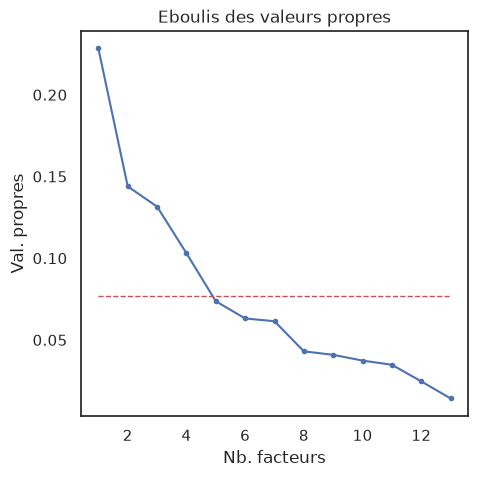

In [305]:
#librairie graphique
import matplotlib.pyplot as plt
#éboulis des v.p.
fix,ax = plt.subplots(figsize=(5,5))
ax.plot(range(1,Hmax+1),acm.eig_[0],".-")
ax.set_xlabel("Nb. facteurs")
ax.set_ylabel("Val. propres")
plt.title("Eboulis des valeurs propres")
#seuil - Règle de Kaiser
ax.plot([1,Hmax],[1/p,1/p],"r--",linewidth=1)
plt.show()

## Correction de Benzecri

In [306]:
#récupérer les valeurs propres supérieur à (1/p)
lambada = acm.eig_[0][acm.eig_[0]>1/p]
print(lambada)
#appliquer la correction
lambada_prim = ((p/(p-1))*(lambada-1/p))**2
print(lambada_prim)
#faire la somme
S_prim = np.sum(lambada_prim)
print(S_prim)

[0.22830403 0.14393175 0.13156134 0.1030571 ]
[0.0268947  0.00526971 0.00350363 0.00080156]
0.03646959400969207


In [307]:
#et produire les pourcentages
percent_prim = lambada_prim/S_prim*100
#affichage

eigen_val_benz = pd.DataFrame(np.transpose(np.array([lambada_prim,percent_prim,np.cumsum(percent_prim)])),columns=['Val.P','%','Cumul %'],index=range(1,len(lambada)+1))
eigen_val_benz

,Val.P,%,Cumul %
1,0.026895,73.745542,73.745542
2,0.005270,14.449585,88.195128
3,0.003504,9.606982,97.802110
4,0.000802,2.197890,100.000000


In [308]:
#somme corrigée de Greenacre (S’’)
S2nd = p/(p-1)*(np.sum(acm.eig_[0]**2)-(M-p)/(p**2))
print(S2nd)
#pourcentage corrigé Greenacre
percent_2nd = lambada_prim/S2nd

#affichage
eigen_val_greenacre = pd.DataFrame(np.transpose(np.array([lambada_prim,percent_2nd,np.cumsum(percent_2nd)])),columns=['Val.P','%','Cumul %'],index=range(1,len(lambada)+1))
print(eigen_val_greenacre)

0.047635449804062716
      Val.P         %   Cumul %
1  0.026895  0.564594  0.564594
2  0.005270  0.110626  0.675220
3  0.003504  0.073551  0.748771
4  0.000802  0.016827  0.765598


In [309]:
#affichage des coordonnées
print(pd.DataFrame(acm.col_coord_[:,:2],index=X.columns,columns=['Coord.F1','Coord.F2']))

                                             Coord.F1  Coord.F2
Aucun logiciel_Non                          -0.375126  0.045793
Aucun logiciel_Oui                           1.410472 -0.172184
Données d'enquête_Non                        0.589319 -0.234436
Données d'enquête_Oui                       -0.523839  0.208388
Données d'entretien_Non                      0.673485 -0.322537
Données d'entretien_Oui                     -0.424388  0.203242
Données du web_Non                           0.211689  0.272225
Données du web_Oui                          -0.987884 -1.270385
Données expérimentales ou d'observation_Non  0.533738 -0.347857
Données expérimentales ou d'observation_Oui -0.490695  0.319804
Données géographiques ou spatiales_Non       0.102882 -0.008738
Données géographiques ou spatiales_Oui      -0.771619  0.065533
Données multimédia_Non                       0.160815  0.281664
Données multimédia_Oui                      -0.709048 -1.241884
Données statistiques_Non                

In [310]:
df_rows = acm.row_topandas()


df_cols = acm.col_topandas()
dict_lab_short = {}
for lab in df_cols.index:
    lab_split = lab.split("_")
    dict_lab_short[lab] = "_".join(lab_split[1:])

df_cols["label"] = df_cols.index.map(dict_lab_short.get)
df_cols[["label",'col_contrib_dim1', 'col_contrib_dim2','col_cos2_dim1',
       'col_cos2_dim2']].sort_values('col_contrib_dim1', ascending=False)



,label,col_contrib_dim1,col_contrib_dim2,col_cos2_dim1,col_cos2_dim2
Aucun logiciel_Aucun logiciel_Oui,Aucun logiciel_Oui,14.082023,0.332871,0.529104,0.007885
excel_excel_Non,excel_Non,9.930163,1.272633,0.443949,0.035869
Données d'entretien_Données d'entretien_Non,Données d'entretien_Non,5.907588,2.149162,0.285819,0.065553
Données statistiques_Données statistiques_Oui,Données statistiques_Oui,5.814988,0.001857,0.285246,0.000057
Données du web_Données du web_Oui,Données du web_Oui,5.802666,15.220995,0.209125,0.345831
r_r_Oui,r_Oui,5.541729,6.361727,0.241637,0.174879
Données d'enquête_Données d'enquête_Non,Données d'enquête_Non,5.506612,1.382264,0.308708,0.048854
excel_excel_Oui,excel_Oui,5.027931,0.644371,0.443949,0.035869
Données d'enquête_Données d'enquête_Oui,Données d'enquête_Oui,4.894766,1.228679,0.308708,0.048854
Données expérimentales ou d'observation_Données expérimentales ou d'observation_Non,Données expérimentales ou d'observation_Non,4.597557,3.097634,0.261902,0.111246


## Projection des variables illustratives

Calcul des coordonnées des variables illustratives et coefficient de corrélation

## Coefficient de corrélation avec facteur des variables illustratives

In [311]:
for factor in range(len(eigen_val_greenacre)):
    Dillustratives[f"F{factor+1}"] = acm.row_coord_[:,factor:factor+1]
Dillustratives

,Aucune,"Autre, précisez lesquelles",jamovi,nvivo,sas,spss,stata,zotero,label_recherche_1,hc_label,hc_methodo_9,hc_methodo_8,hc_methodo_6,clust_type_data,F1,F2,F3,F4
q45_clé,,,,,,,,,,,,,,,,,,
2DRU-P3AV,Aucune_Non,"Autre, précisez lesquelles_Non",jamovi_Non,nvivo_Non,sas_Non,spss_Non,stata_Non,zotero_Non,Psychologie,MIASSH,Données mixtes,Analyse de données mixtes,Analyse de données mixtes,Données du web et statistiques,-0.722567,-0.905751,-0.261661,-0.315708
2JQN-P9PA,Aucune_Non,"Autre, précisez lesquelles_Non",jamovi_Non,nvivo_Non,sas_Non,spss_Non,stata_Non,zotero_Non,Psychologie,Psychologie,Données expérimentales avec R,Données expérimentales avec R,Analyse de données avec R,Etudes expérimentale,0.077996,0.416962,0.459519,0.071251
2QNC-8AAQ,Aucune_Non,"Autre, précisez lesquelles_Non",jamovi_Non,nvivo_Non,sas_Non,spss_Non,stata_Non,zotero_Non,"Individus, normes, société",Dynamiques spaciales,Analyses manuelles de textes,Analyses manuelles de textes,Analyses manuelles des données,Entretiens,0.553676,0.016438,-0.535029,-0.257750
2Y89-7BR9,Aucune_Non,"Autre, précisez lesquelles_Non",jamovi_Non,nvivo_Non,sas_Non,spss_Non,stata_Non,zotero_Non,Psychologie,"Langues, langage et communication",Données d'entretiens avec excel,Données d'entretien avec excel,Données d'entretien avec excel,Entretiens,0.218345,0.052140,-0.251576,0.337182
32TW-JLY5,Aucune_Non,"Autre, précisez lesquelles_Non",jamovi_Non,nvivo_Non,sas_Non,spss_Non,stata_Non,zotero_Non,Sciences informatiques,MIASSH,Données mixtes,Analyse de données mixtes,Analyse de données mixtes,Données du web et statistiques,-0.580148,-0.706255,0.021294,-0.329193
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,Aucune_Non,"Autre, précisez lesquelles_Non",jamovi_Non,nvivo_Non,sas_Non,spss_Non,stata_Non,zotero_Non,Histoires sociales du politique,Questions économiques,Données mixtes,Analyse de données mixtes,Analyse de données mixtes,Données statistiques et textutelles,-0.329873,-0.167708,-0.415719,0.099372
YTMC-B4DP,Aucune_Non,"Autre, précisez lesquelles_Non",jamovi_Oui,nvivo_Non,sas_Non,spss_Non,stata_Non,zotero_Non,Psychologie sociale,Psychologie,Données expérimentales avec R,Données expérimentales avec R,Analyse de données avec R,Données statistiques et observations,-0.593889,0.307585,0.136809,-0.320143
ZB5S-ABHN,Aucune_Non,"Autre, précisez lesquelles_Non",jamovi_Non,nvivo_Non,sas_Non,spss_Non,stata_Non,zotero_Non,Psychologie,"Langues, langage et communication",Données expérimentales avec R,Données expérimentales avec R,Analyse de données avec R,Données statistiques et observations,-0.274642,0.526711,0.396362,-0.054106


In [312]:



i=-1
for n, var in enumerate(var_illust):
    i+=1
    # définition des coordonnées
    GBar = pd.pivot_table(Dillustratives,values=[f"F{f+1}" for f in range(len(eigen_val_greenacre))],index=var,aggfunc='mean') # moyenne des coordonnées 
    Gv0 = GBar.values/np.sqrt(acm.eig_[0,0:1])
    Gv0 = pd.DataFrame(Gv0,index=GBar.index,columns=GBar.columns)
    Gv0["variable"]=var

    

    n_g = pd.pivot_table(Dillustratives,values=['F1'],index=var,aggfunc='count') #effectif par 
    n = np.sum(n_g.F1)
    dict_corr = {"variable":var}

    for f in range(len(eigen_val_greenacre)):
        dict_corr[f"F{f+1}"] = np.sum((n_g.F1/n)*(GBar[f"F{f+1}"]**2))/acm.eig_[0][0]
        


    df_corr0 = pd.DataFrame.from_dict([dict_corr])
    df_corr0 = df_corr0.set_index("variable")

    if i == 0:
        Gv = Gv0.copy()
        df_corr = df_corr0.copy()
    else:
        Gv = pd.concat([Gv,Gv0])
        df_corr = pd.concat([df_corr, df_corr0])


In [313]:
import matplotlib.cm as cm
import matplotlib as mpl




In [314]:
df_corr

,F1,F2,F3,F4
variable,,,,
Aucune,0.111956,0.002386,0.020966,0.001220
"Autre, précisez lesquelles",0.000128,0.006623,0.001115,0.008384
jamovi,0.024057,0.067073,0.004927,0.002738
nvivo,0.000953,0.011241,0.014163,0.004981
sas,0.044823,0.000819,0.001051,0.000397
spss,0.013783,0.027432,0.003689,0.007620
stata,0.010136,0.000483,0.030305,0.000015
zotero,0.009739,0.000043,0.005686,0.006780
label_recherche_1,0.256662,0.178769,0.120817,0.093619


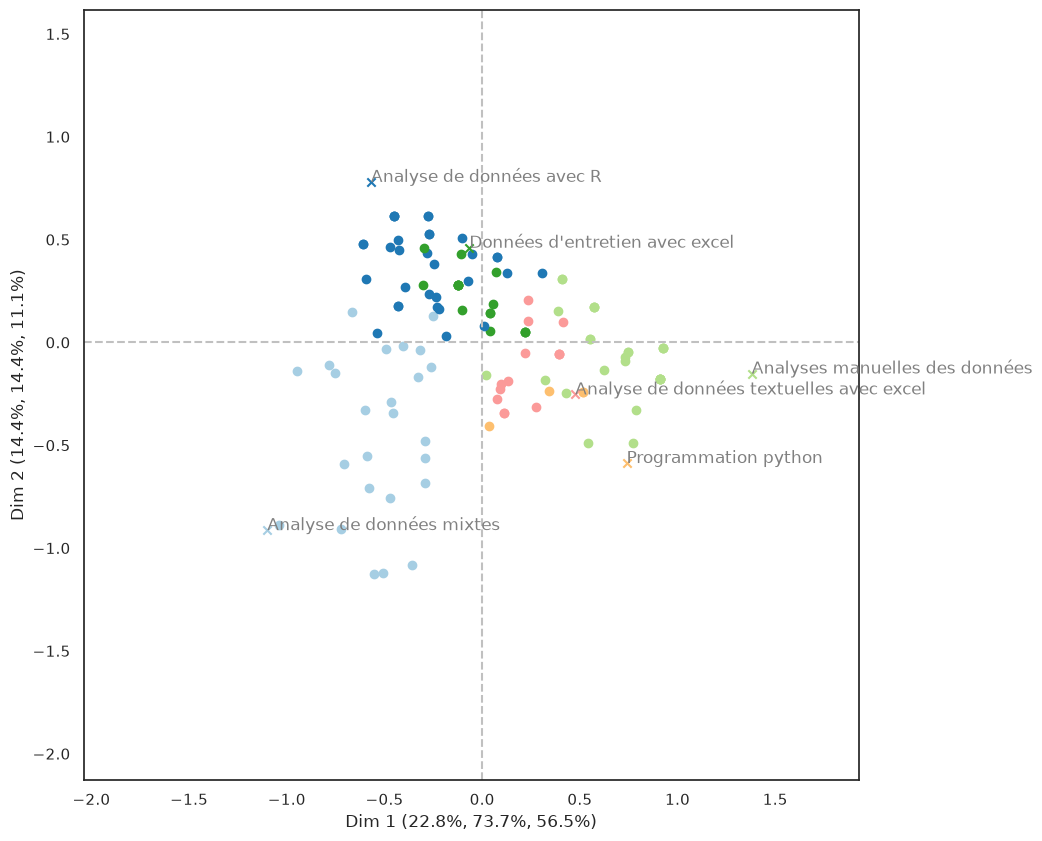

In [318]:
#représentation dans le plan
fix,ax = plt.subplots(figsize=(10,10))

dim_x = 1
dim_y = 2
min_abs = np.min(df_rows[f"row_coord_dim{dim_x}"])-1
max_abs = np.max(df_rows[f"row_coord_dim{dim_x}"])+1
min_ord = np.min(df_rows[f"row_coord_dim{dim_y}"])-1
max_ord = np.max(df_rows[f"row_coord_dim{dim_y}"])+1



show_var_illustratives = True
var_illustratives = ["hc_methodo_6"]


    

cmap = mpl.colormaps['Paired']
colors_map = cmap(np.linspace(0, 1, 11))

dict_mod_id = {}
for n, mod in enumerate(Dillustratives[var_illustratives[0]].unique()):
    dict_mod_id[mod] = n

Dillustratives["id_label"] = Dillustratives[var_illustratives[0]].map(dict_mod_id.get)
c_label =[colors_map[i] for i in Dillustratives.id_label]


# Plan factoriel
ax.axis([min_abs, max_abs,min_ord, max_ord])
ax.plot([min_abs,max_abs],[0,0],color='silver',linestyle='--')
ax.plot([0,0],[min_ord, max_ord],color='silver',linestyle='--')

ax.set_xlabel(f"Dim {dim_x} ({round(valeurs_propres.iloc[dim_x-1, 1], 1)}%, {round(eigen_val_benz.iloc[dim_x-1, 1], 1)}%, {round(eigen_val_greenacre.iloc[dim_x-1, 1]*100, 1)}%)")
ax.set_ylabel(f"Dim {dim_y} ({round(valeurs_propres.iloc[dim_y-1, 1], 1)}%, {round(eigen_val_benz.iloc[dim_y-1, 1], 1)}%, {round(eigen_val_greenacre.iloc[dim_y-1, 1]*100, 1)}%)")

#ax[0].subtitle("Représentation des points-modalités")
for i in range(df_rows.shape[0]):
    ax.scatter(acm.row_coord_[i,dim_x-1],acm.row_coord_[i,dim_y-1],color=c_label[i])

if show_var_illustratives == True:
    for var in var_illustratives:
        Gv1 = Gv.loc[Gv.variable == var]
        for i in Gv1.index:
            x = Gv1.loc[i].iloc[dim_x-1]
            y = Gv1.loc[i].iloc[dim_y-1]
            ax.scatter(x,y,color=colors_map[dict_mod_id[i]], marker="x")
            ax.text(x,y,i,color="grey")


else:
    pass




plt.show()

## Graphique des variables

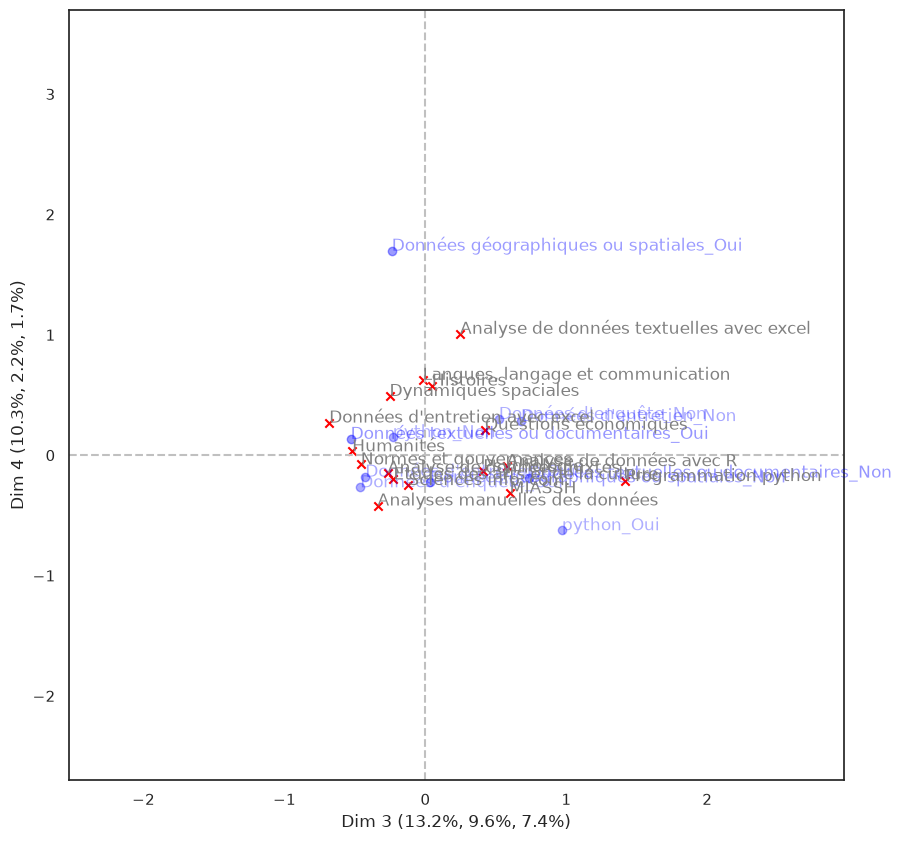

In [354]:
#représentation dans le plan
fix,ax = plt.subplots(figsize=(10,10))

dim_x = 3
dim_y = 4
min_abs = np.min(df_cols[f"col_coord_dim{dim_x}"])-2
max_abs = np.max(df_cols[f"col_coord_dim{dim_x}"])+2
min_ord = np.min(df_cols[f"col_coord_dim{dim_y}"])-2
max_ord = np.max(df_cols[f"col_coord_dim{dim_y}"])+2

show_var_illustratives = True
var_illustratives = ["hc_methodo_6","hc_label"]


cmap = mpl.colormaps['Paired']
colors_map = cmap(np.linspace(0, 1, 11))

dict_mod_id = {}
for n, mod in enumerate(Dillustratives[var_illustratives[0]].unique()):
    dict_mod_id[mod] = n

Dillustratives["id_label"] = Dillustratives[var_illustratives[0]].map(dict_mod_id.get)
c_label =[colors_map[i] for i in Dillustratives.id_label]

# Plan factoriel
ax.axis([min_abs, max_abs,min_ord, max_ord])
ax.plot([min_abs,max_abs],[0,0],color='silver',linestyle='--')
ax.plot([0,0],[min_ord, max_ord],color='silver',linestyle='--')

ax.set_xlabel(f"Dim {dim_x} ({round(valeurs_propres.iloc[dim_x-1, 1], 1)}%, {round(eigen_val_benz.iloc[dim_x-1, 1], 1)}%, {round(eigen_val_greenacre.iloc[dim_x-1, 1]*100, 1)}%)")
ax.set_ylabel(f"Dim {dim_y} ({round(valeurs_propres.iloc[dim_y-1, 1], 1)}%, {round(eigen_val_benz.iloc[dim_y-1, 1], 1)}%, {round(eigen_val_greenacre.iloc[dim_y-1, 1]*100, 1)}%)")

df_cols["cos_cumsum"] = df_cols[f"col_cos2_dim{dim_x}"]+df_cols[f"col_cos2_dim{dim_y}"]
df_cols1 = df_cols.loc[df_cols["cos_cumsum"]>0.3]

#ax[0].subtitle("Représentation des points-modalités")
for i in range(df_cols1.shape[0]):
    ax.scatter(df_cols1[f"col_coord_dim{dim_x}"].iloc[i],df_cols1[f"col_coord_dim{dim_y}"].iloc[i],color="blue", alpha=df_cols1["cos_cumsum"].iloc[i])
    ax.text(df_cols1[f"col_coord_dim{dim_x}"].iloc[i],df_cols1[f"col_coord_dim{dim_y}"].iloc[i],df_cols1.label.iloc[i],color="blue",  alpha=df_cols1["cos_cumsum"].iloc[i])

if show_var_illustratives ==True:
    for var in var_illustratives:
        Gv1 = Gv.loc[Gv.variable == var]
        for i in Gv1.index:
            x = Gv1.loc[i].iloc[dim_x-1]
            y = Gv1.loc[i].iloc[dim_y-1]
            ax.scatter(x,y,color="red", marker="x")
            ax.text(x,y,i,color="grey")
else:
    pass




plt.show()

In [322]:
import datamapplot

In [346]:
df_coord= pd.DataFrame(acm.row_coord_[:,2:4],index=X.index,columns=['F1','F2'])
df_coord['hc_methodo_6'] = Dillustratives.hc_methodo_6
df_coord.loc[df_coord.hc_methodo_6.isna(), "hc_methodo_6"]= "non-label"

dict_hc_label={}
for n, x in enumerate(df_coord.hc_methodo_6.unique()):
    dict_hc_label[x] = n
df_coord["id_hc_label"] = df_coord.hc_methodo_6.map(dict_hc_label.get)
lab = [i for n, i in enumerate(df_coord.hc_methodo_6)]

data_map = acm.row_coord_[:,2:4]
data_map.shape
data_label = np.array(lab, dtype="object")


(<Figure size 1000x1000 with 1 Axes>, <Axes: >)

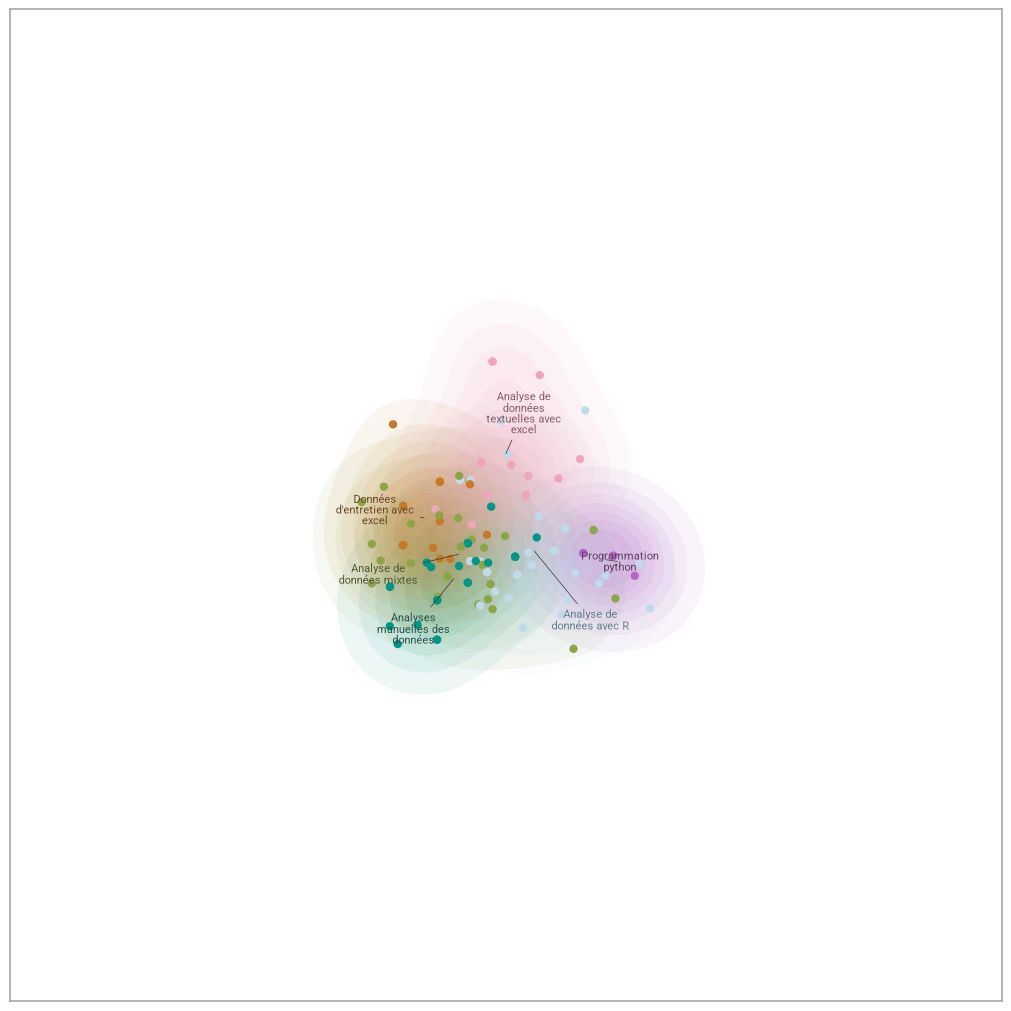

In [347]:
datamapplot.create_plot(data_map, data_label)

In [348]:
#récupération des contribution sous une forme exploitable - 2 facteurs
contrib12 = pd.DataFrame(acm.col_contrib_[:,:4],index=X.columns)
print(contrib12)

#**calcul des carrés des rapports de corrélation par variable sur les 2 facteurs**
#structure pour les eta2
#structure pour les eta2
cols=len(table[var_active].columns)
eta2 = np.zeros((cols,4))
#pour chaque facteur
for h in range(4):
    #pour chaque variable
    for j in range(cols):
        eta2[j,h] = (p*acm.eig_[0][h]*np.sum(contrib12.loc[np.unique(table[var_active].iloc[:,j])][h]))/100
            #affichage

print(pd.DataFrame(eta2,index=table[var_active].columns[:],columns=['F1','F2','F3','F4']))



                                                     0          1          2  \
Aucun logiciel_Non                            3.745219   0.088530   0.787043   
Aucun logiciel_Oui                           14.082023   0.332871   2.959281   
Données d'enquête_Non                         5.506612   1.382264   7.459638   
Données d'enquête_Oui                         4.894766   1.228679   6.630789   
Données d'entretien_Non                       5.907588   2.149162  10.378917   
Données d'entretien_Oui                       3.722590   1.354266   6.540140   
Données du web_Non                            1.243428   3.261642   0.535033   
Données du web_Oui                            5.802666  15.220995   2.496822   
Données expérimentales ou d'observation_Non   4.597557   3.097634   0.000095   
Données expérimentales ou d'observation_Oui   4.226786   2.847825   0.000088   
Données géographiques ou spatiales_Non        0.314679   0.003600   0.052478   
Données géographiques ou spatiales_Oui  

In [349]:
eta2

array([[5.29104042e-01, 7.88488565e-03, 6.40732786e-02, 1.23542229e-01],
       [3.08707971e-01, 4.88537041e-02, 2.40988199e-01, 8.03101345e-02],
       [2.85819097e-01, 6.55530903e-02, 2.89366190e-01, 5.04942100e-02],
       [2.09124735e-01, 3.45830982e-01, 5.18537476e-02, 1.91493598e-02],
       [2.61902293e-01, 1.11246251e-01, 3.12646726e-06, 2.17702388e-01],
       [7.93860518e-02, 5.72601605e-04, 7.62904701e-03, 3.84713057e-01],
       [1.14025533e-01, 3.49794658e-01, 8.70556895e-03, 4.43493013e-02],
       [2.85246413e-01, 5.74276963e-05, 1.55573539e-01, 9.09787671e-04],
       [2.90238961e-03, 1.40881142e-01, 3.89147286e-01, 2.52307281e-02],
       [1.16519817e-01, 3.36443259e-01, 5.02262367e-02, 3.13389348e-02],
       [4.43949121e-01, 3.58693093e-02, 1.60664129e-02, 2.47082446e-01],
       [8.96275709e-02, 2.53246788e-01, 2.24475662e-01, 9.32888070e-02],
       [2.41637400e-01, 1.74878714e-01, 2.12189081e-01, 2.16309548e-02]])

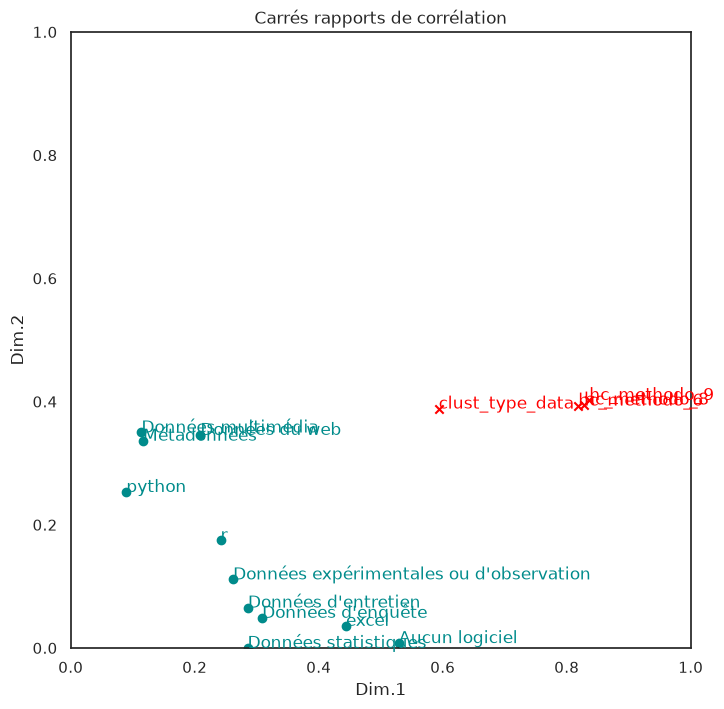

In [353]:
fix,ax = plt.subplots(figsize=(8,8))

dim_x = 1
dim_y = 2

ax.axis([0,+1,0,+1])
ax.set_xlabel("Dim.1")
ax.set_ylabel("Dim.2")
plt.title("Carrés rapports de corrélation")
for i in range(cols):
    x = eta2[i,dim_x-1]
    y = eta2[i,dim_y-1]
    if x > 0.2 or y > 0.2:
        ax.scatter(eta2[i,dim_x-1],eta2[i,dim_y-1],color='darkcyan')
        ax.text(eta2[i,dim_x-1],eta2[i,dim_y-1],df_os[var_active].columns[i],color='darkcyan')

corr_ill = np.array(df_corr)
for n, i in enumerate(df_corr.index):
    x= corr_ill[n,dim_x-1]
    y= corr_ill[n,dim_y-1]
    if x > 0.4 or y > 0.4:
        ax.scatter(x,y, color='red', marker="x")
        ax.text(x,y, i,color='red')
plt.show()

In [60]:
print(df0.auto_lab_research_cluster.value_counts().to_markdown())

| auto_lab_research_cluster                                                                                                                            |   count |
|:-----------------------------------------------------------------------------------------------------------------------------------------------------|--------:|
| ["SH4 L'esprit humain et sa complexité", 'SH8 Études des cultures et des arts', 'SH5 Textes et concepts']                                            |      19 |
| ["SH4 L'esprit humain et sa complexité", 'LS5 Neurosciences et troubles du système nerveux', 'SH5 Textes et concepts']                               |      18 |
| ['SH2 Institutions, gouvernance et systèmes juridiques', 'SH1 Individus, marchés et organisations', 'SH7 Mobilité humaine, environnement et espace'] |      16 |
| ['SH5 Textes et concepts', 'SH8 Études des cultures et des arts', "SH6 L'étude du passé humain"]                                                     |      13 |
| ['SH8 Études des cul

In [48]:
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram, linkage

In [49]:
# Extract the row coordinates (numerical representation of your rows)
acm.row_coord_



array([[-0.72256736, -0.90575112, -0.26166071, ...,  0.15163885,
        -0.03182127,  0.08015102],
       [ 0.07799575,  0.41696199,  0.45951917, ...,  0.11307048,
        -0.12095248,  0.08658359],
       [ 0.55367644,  0.01643824, -0.53502854, ..., -0.22904942,
         0.03616351,  0.0213383 ],
       ...,
       [-0.27464151,  0.52671115,  0.39636235, ...,  0.04466751,
        -0.29699177,  0.06617175],
       [ 0.03530342, -0.40441752,  0.85490007, ...,  0.415408  ,
         0.20525281, -0.16274239],
       [-1.03924385, -0.88754904, -0.14803723, ...,  0.25284693,
        -0.05274527,  0.09199928]], shape=(119, 13))

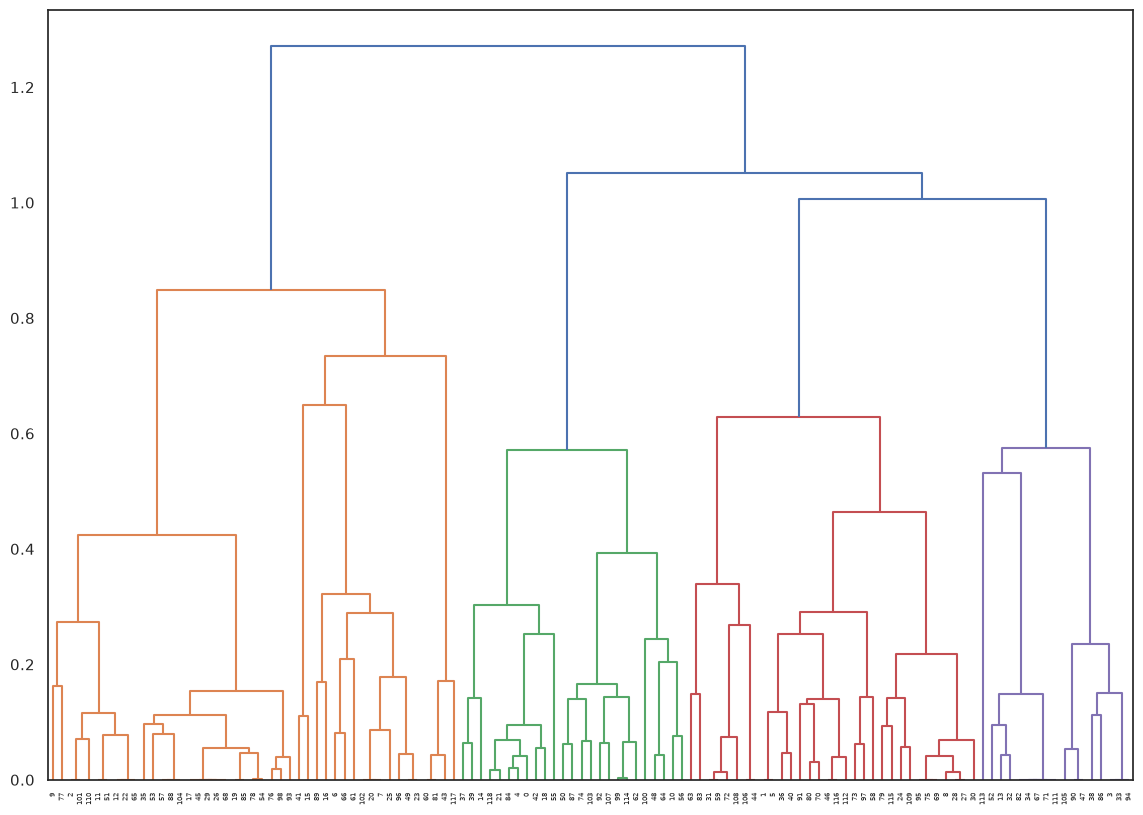

In [128]:


x = [4, 5, 10, 4, 3, 11, 14 , 6, 10, 12]
y = [21, 19, 24, 17, 16, 25, 24, 22, 21, 21]

data = list(zip(x, y))

linkage_data = linkage(acm.row_coord_[:,0:4], method='average', metric='cosine', optimal_ordering=True)

dendrogram(linkage_data)

plt.show() 

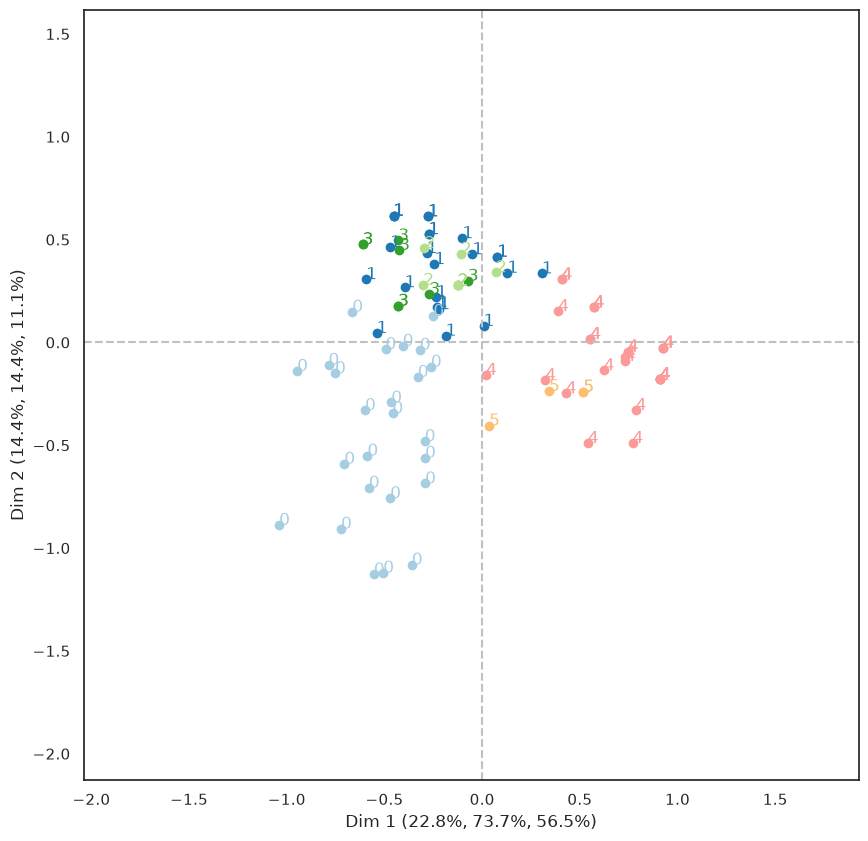

In [259]:
#représentation dans le plan
from sklearn.cluster import AgglomerativeClustering

x = acm.row_coord_[:,0]
y = acm.row_coord_[:,1]

data = list(zip(x, y))

hierarchical_cluster = AgglomerativeClustering(n_clusters=9, metric="cosine",linkage="average")
labels = hierarchical_cluster.fit_predict(acm.row_coord_[:,:4])
kmeans = KMeans(n_clusters=8, random_state=42, n_init='auto')
labels_k = kmeans.fit_predict(acm.row_coord_[:,:4])


fix,ax = plt.subplots(figsize=(10,10))

dim_x = 1
dim_y = 2
min_abs = np.min(df_rows[f"row_coord_dim{dim_x}"])-1
max_abs = np.max(df_rows[f"row_coord_dim{dim_x}"])+1
min_ord = np.min(df_rows[f"row_coord_dim{dim_y}"])-1
max_ord = np.max(df_rows[f"row_coord_dim{dim_y}"])+1



cmap = mpl.colormaps['Paired']
colors_map = cmap(np.linspace(0, 1, 11))

c_label =[colors_map[i] for i in labels]

# Plan factoriel
ax.axis([min_abs, max_abs,min_ord, max_ord])
ax.plot([min_abs,max_abs],[0,0],color='silver',linestyle='--')
ax.plot([0,0],[min_ord, max_ord],color='silver',linestyle='--')

ax.set_xlabel(f"Dim {dim_x} ({round(valeurs_propres.iloc[dim_x-1, 1], 1)}%, {round(eigen_val_benz.iloc[dim_x-1, 1], 1)}%, {round(eigen_val_greenacre.iloc[dim_x-1, 1]*100, 1)}%)")
ax.set_ylabel(f"Dim {dim_y} ({round(valeurs_propres.iloc[dim_y-1, 1], 1)}%, {round(eigen_val_benz.iloc[dim_y-1, 1], 1)}%, {round(eigen_val_greenacre.iloc[dim_y-1, 1]*100, 1)}%)")

#ax[0].subtitle("Représentation des points-modalités")
for i in range(len(c_label)):
    
    if labels[i]<6:
        ax.scatter(acm.row_coord_[i,dim_x-1],acm.row_coord_[i,dim_y-1],color=c_label[i])
        ax.text(acm.row_coord_[i,dim_x-1],acm.row_coord_[i,dim_y-1], labels[i], color=c_label[i])





plt.show()

In [260]:
DActives["hierarcical_clust_all"] =  hierarchical_cluster.fit_predict(acm.row_coord_[:,:4])
#DActives["hierarcical_clust_all_9"] =  hierarchical_cluster.fit_predict(acm.row_coord_[:,:])

In [264]:
DActives

,Aucun logiciel,Données d'enquête,Données d'entretien,Données du web,Données expérimentales ou d'observation,Données géographiques ou spatiales,Données multimédia,Données statistiques,Données textuelles ou documentaires,Métadonnées,excel,python,r,kmeans,hierarcical_clust_all,hc_methodo_9,hc_methodo_8,hc_methodo_6
q45_clé,,,,,,,,,,,,,,,,,,
2DRU-P3AV,Aucun logiciel_Non,Données d'enquête_Oui,Données d'entretien_Oui,Données du web_Oui,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Oui,Données statistiques_Non,Données textuelles ou documentaires_Oui,Métadonnées_Oui,excel_Oui,python_Oui,r_Non,4,0,Données mixtes,Analyse de données mixtes,Analyse de données mixtes
2JQN-P9PA,Aucun logiciel_Non,Données d'enquête_Non,Données d'entretien_Non,Données du web_Non,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Non,Données textuelles ou documentaires_Non,Métadonnées_Non,excel_Oui,python_Non,r_Oui,5,1,Données expérimentales avec R,Données expérimentales avec R,Analyse de données avec R
2QNC-8AAQ,Aucun logiciel_Oui,Données d'enquête_Oui,Données d'entretien_Oui,Données du web_Non,Données expérimentales ou d'observation_Non,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Non,Données textuelles ou documentaires_Oui,Métadonnées_Non,excel_Non,python_Non,r_Non,3,4,Analyses manuelles de textes,Analyses manuelles de textes,Analyses manuelles des données
2Y89-7BR9,Aucun logiciel_Non,Données d'enquête_Non,Données d'entretien_Oui,Données du web_Non,Données expérimentales ou d'observation_Non,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Non,Données textuelles ou documentaires_Oui,Métadonnées_Non,excel_Oui,python_Non,r_Non,6,8,Données d'entretiens avec excel,Données d'entretien avec excel,Données d'entretien avec excel
32TW-JLY5,Aucun logiciel_Non,Données d'enquête_Oui,Données d'entretien_Non,Données du web_Oui,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Oui,Données statistiques_Oui,Données textuelles ou documentaires_Oui,Métadonnées_Non,excel_Oui,python_Oui,r_Non,4,0,Données mixtes,Analyse de données mixtes,Analyse de données mixtes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,Aucun logiciel_Non,Données d'enquête_Oui,Données d'entretien_Oui,Données du web_Oui,Données expérimentales ou d'observation_Non,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Oui,Données textuelles ou documentaires_Oui,Métadonnées_Non,excel_Oui,python_Non,r_Non,1,0,Données mixtes,Analyse de données mixtes,Analyse de données mixtes
YTMC-B4DP,Aucun logiciel_Non,Données d'enquête_Oui,Données d'entretien_Oui,Données du web_Non,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Oui,Données statistiques_Oui,Données textuelles ou documentaires_Non,Métadonnées_Non,excel_Oui,python_Non,r_Oui,7,1,Données expérimentales avec R,Données expérimentales avec R,Analyse de données avec R
ZB5S-ABHN,Aucun logiciel_Non,Données d'enquête_Non,Données d'entretien_Oui,Données du web_Non,Données expérimentales ou d'observation_Oui,Données géographiques ou spatiales_Non,Données multimédia_Non,Données statistiques_Oui,Données textuelles ou documentaires_Non,Métadonnées_Non,excel_Oui,python_Non,r_Oui,7,1,Données expérimentales avec R,Données expérimentales avec R,Analyse de données avec R


In [262]:
d = DActives.loc[DActives.hierarcical_clust_all==4]
print(len(d))
for x in d.columns[:-3]:
    print(d[x].loc[d[x].str.contains("Oui")].value_counts())
d

27
Aucun logiciel
Aucun logiciel_Oui    25
Name: count, dtype: int64
Données d'enquête
Données d'enquête_Oui    10
Name: count, dtype: int64
Données d'entretien
Données d'entretien_Oui    12
Name: count, dtype: int64
Données du web
Données du web_Oui    2
Name: count, dtype: int64
Données expérimentales ou d'observation
Données expérimentales ou d'observation_Oui    7
Name: count, dtype: int64
Series([], Name: count, dtype: int64)
Données multimédia
Données multimédia_Oui    3
Name: count, dtype: int64
Données statistiques
Données statistiques_Oui    2
Name: count, dtype: int64
Données textuelles ou documentaires
Données textuelles ou documentaires_Oui    17
Name: count, dtype: int64
Métadonnées
Métadonnées_Oui    1
Name: count, dtype: int64
Series([], Name: count, dtype: int64)
Series([], Name: count, dtype: int64)
Series([], Name: count, dtype: int64)


AttributeError: Can only use .str accessor with string values!

In [263]:

dict_label_hc_4d_9 ={0:"Données mixtes",
                1:"Données expérimentales avec R",
                2:"Données qualitatives avec excel",
                3:"Données statistiques avec R",
                4:"Analyses manuelles de textes",
                5:"Programmation python",
                6:"Données multimédia et excel",
                7:"Analyse de données textuelles avec excel",
                8:"Données d'entretiens avec excel"
                   }

dict_label_hc_4d_8 ={0:"Données d'entretien avec excel",
                1:"Données expérimentales avec R",
                2:"Analyse de données mixtes",
                3:"Données statistiques avec R",
                4:"Analyses manuelles de textes",
                5:"Programmation python",
                6:"Données multimédia et excel",
                7:"Analyse de données textuelles avec excel"
                   }


dict_label_hc_4d_6 ={0:"Analyse de données textuelles avec excel",
                1:"Analyse de données avec R",
                2:"Analyse de données mixtes",
                3:"Données d'entretien avec excel",
                4:"Analyses manuelles des données",
                5:"Programmation python"
                   }

    
DActives["hc_methodo_9"]=DActives.hierarcical_clust_all.map(dict_label_hc_4d_9.get)


In [267]:
df02 = df0.merge(DActives[["hc_methodo_9","hc_methodo_8","hc_methodo_6"]].reset_index(), on=["q45_clé"], how = "left")
df02

,qno_obs,q1_so_principles,q2_hal_depot,q3_octavi_depot,q4_diff_data,q4_autres_entrepots,q5_r,q5_python,q5_excel,q5_julia,...,clust_type_data,auto_clust_data,label_clust_metho_data_kneig_4,auto_metho_data_kneig_4,label_clust_metho_data_kneig_5,auto_metho_data_kneig_5,hc_label,hc_methodo_9,hc_methodo_8,hc_methodo_6
0,1,"Oui, un peu","Oui, une fois",Non,Non,NaN,Non,Non,Non,Non,...,Données textuelles et observations,"['Données textuelles ou documentaires', ""Donné...",NaN,NaN,NaN,NaN,NaN,Analyses manuelles de textes,Analyses manuelles de textes,Analyses manuelles des données
1,2,"Oui, un peu","Oui, une fois",Non,Non,NaN,Non,Non,Non,Non,...,Corpus textuels,"['Données textuelles ou documentaires', 'Métad...",Méthodes mixtes,"excel, Métadonnées, Données statistiques",Collecte et analyse de traces numériques,"Données statistiques, python, Données du web",Humanités,Analyses manuelles de textes,Analyses manuelles de textes,Analyses manuelles des données
2,3,"Oui, tout à fait","Oui, plusieurs fois",Je ne connais pas Octaviana,Non,NaN,Non,Non,Oui,Non,...,Entretiens,"['Données textuelles ou documentaires', 'Autre...",Enquêtes qualitatives et entretien,"Données textuelles ou documentaires, Données d...",Enquête par entretien,"Données textuelles ou documentaires, excel, Do...",Psychologie,Données d'entretiens avec excel,Données d'entretien avec excel,Données d'entretien avec excel
3,4,"Oui, un peu","Oui, une fois",Non,"Autre, précisez",OSF,Oui,Non,Non,Non,...,Etudes expérimentale,"[""Données expérimentales ou d'observation"", ""D...",Analyse de données expérimentales,"Données statistiques, Données expérimentales o...",Approches expérimentales,"Données statistiques, r, excel",Psychologie,Données expérimentales avec R,Données expérimentales avec R,Analyse de données avec R
4,5,"Oui, un peu","Oui, systématiquement",Non,Non,NaN,Non,Non,Oui,Non,...,Données du web et statistiques,"['Données statistiques', 'Données du web', 'Do...",Méthodes mixtes,"excel, Métadonnées, Données statistiques",Enquête par entretien,"Données textuelles ou documentaires, excel, Do...",Questions économiques,Analyse de données textuelles avec excel,Analyse de données textuelles avec excel,Analyse de données textuelles avec excel
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,117,"Oui, un peu","Oui, plusieurs fois",Non,"Autre, précisez",OSF,Oui,Oui,Oui,Non,...,Données statistiques et observations,"['Données statistiques', ""Données expérimental...",Approches expérimentales/cliniques,"Données expérimentales ou d'observation, excel, r",Approches expérimentales,"Données statistiques, r, excel",Psychologie,Données expérimentales avec R,Données expérimentales avec R,Analyse de données avec R
115,118,"Oui, un peu","Oui, systématiquement",Non,Non,NaN,Oui,Non,Oui,Non,...,Données du web et statistiques,"['Données statistiques', 'Données du web', 'Do...",Méthodes mixtes II,"Données statistiques, Données textuelles ou do...",Méthodes mixtes,"Données statistiques, Données textuelles ou do...",Normes et gouvernances,Données mixtes,Analyse de données mixtes,Analyse de données mixtes
116,119,"Oui, un peu","Oui, plusieurs fois",Non,Non,NaN,Oui,Non,Oui,Non,...,Données statistiques et textutelles,"['Données statistiques', 'Données textuelles o...",Méthodes mixtes II,"Données statistiques, Données textuelles ou do...",Méthodes mixtes,"Données statistiques, Données textuelles ou do...",Normes et gouvernances,Données statistiques avec R,Données statistiques avec R,Analyse de données avec R
117,120,Non,"Oui, plusieurs fois",Non;Je ne connais pas Octaviana,"Autre, précisez",Mendeley data,Non,Oui,Oui,Non,...,Données du web et statistiques,"['Données statistiques', 'Données du web', 'Do...",Collectes et analyses de traces numériques,"Données du web, Données multimédia, Données st...",Collecte et analyse de traces numériques,"Données statistiques, python, Données du web",MIASSH,Données mixtes,Analyse de données mixtes,Analyse de données mixtes


In [268]:
# on enregistre les nouvelles variables dans le dataframe original
with fs.open(f"{BUCKET_OUT}/data_eP8/raw/{last_file}", "w") as file_out:
    df02.to_csv(file_out, sep=",", index= False)

In [269]:
dic_new_var = {'name':"Données traitées",
               'label':'hc_methodo_9',
               'group':'type de données produites',
               'personal_data':False,
               'type':'simple_nominal',
               'opened_question':False,
               'type_panda':df0.hc_label.dtypes,
               'no_question':109,
               'question':"",
               'question_family':'',
               'comment':"Label donnés manuellement aux clusters des groupes de méthodes (n=9) identifiés par une classification hiérarchique ascendante après analyse en composantes multiple"
              }
new_variable = pd.DataFrame.from_dict(data=[dic_new_var])
new_variable
df_col1 = pd.concat([df_col,new_variable], ignore_index = True)
df_col1

,name,label,group,personal_data,type,opened_question,type_panda,no_question,question,question_family,comment
0,N°Obs,qno_obs,NaN,False,numérique,False,int64,0.0,NaN,qno,NaN
1,1. so_principles,q1_so_principles,1_connaissance_so,False,ordinal,False,object,1.0,1/ Diriez-vous que vous êtes familier.ère des ...,q1,NaN
2,2. hal_depot,q2_hal_depot,1_connaissance_so,False,ordinal,False,object,2.0,2/ Avez-vous déjà déposé une production scient...,q2,NaN
3,3. octavi_depot,q3_octavi_depot,2_bib_num,False,nominal_multiple,False,object,3.0,3/ Avez-vous des productions déposées sur Octa...,q3,NaN
4,4. open_data,q4_diff_data,3_entrepot,False,nominal_multiple,False,object,4.0,4/ Avez-vous déjà diffusé vos données de reche...,q4,NaN
...,...,...,...,...,...,...,...,...,...,...,...
159,Champ de recherche,research_fields,champ de recherche,False,simple_nominal,False,object,109.0,NaN,NaN,liste des champs de recherche sélectionné avec...
160,Style de données,clust_type_data,Type de données,False,simple_nominal,False,object,28.0,NaN,NaN,Label donnés manuellement aux clusters de données
161,Style de données,auto_clust_data,Type de données,False,simple_nominal,False,object,28.0,NaN,NaN,Label donnés automatiquement aux clusters de d...
162,Aire de rechere,hc_label,champ de recherche,False,simple_nominal,False,object,109.0,NaN,NaN,Label donnés manuellement aux clusters des cha...


In [270]:
dic_new_var = {'name':"Données traitées",
               'label':'hc_methodo_8',
               'group':'type de données produites',
               'personal_data':False,
               'type':'simple_nominal',
               'opened_question':False,
               'type_panda':df0.hc_label.dtypes,
               'no_question':109,
               'question':"",
               'question_family':'',
               'comment':"Label donnés manuellement aux clusters des groupes de méthodes (n=8) identifiés par une classification hiérarchique ascendante après analyse en composantes multiple"
              }
new_variable = pd.DataFrame.from_dict(data=[dic_new_var])
new_variable
df_col2 = pd.concat([df_col1,new_variable], ignore_index = True)


In [271]:
dic_new_var = {'name':"Données traitées",
               'label':'hc_methodo_6',
               'group':'type de données produites',
               'personal_data':False,
               'type':'simple_nominal',
               'opened_question':False,
               'type_panda':df0.hc_label.dtypes,
               'no_question':109,
               'question':"",
               'question_family':'',
               'comment':"Label donnés manuellement aux clusters des groupes de méthodes (n=6) identifiés par une classification hiérarchique ascendante après analyse en composantes multiple"
              }
new_variable = pd.DataFrame.from_dict(data=[dic_new_var])
new_variable
df_col3 = pd.concat([df_col2,new_variable], ignore_index = True)


In [272]:
df_col3.to_csv("../le_questionnaire/dico_variable.csv", sep=",", index= False)